# Case 2
Case 2: $b>0$ and $c>1$

If $b>1$, the $p$ and $q$ that equate payoffs are
\begin{alignat*}{1}
    p &= \frac{b^2(1-b)}{(b+c-1)\Bigl[(1-b)(b+c)-c(c-b)\Bigr]}\\[6pt]
    q &= \frac{c-b-(1-b)p}{c}
\end{alignat*}
It remains to be checked when $p,q\in[0,1]$.

NameError: name 'inside' is not defined

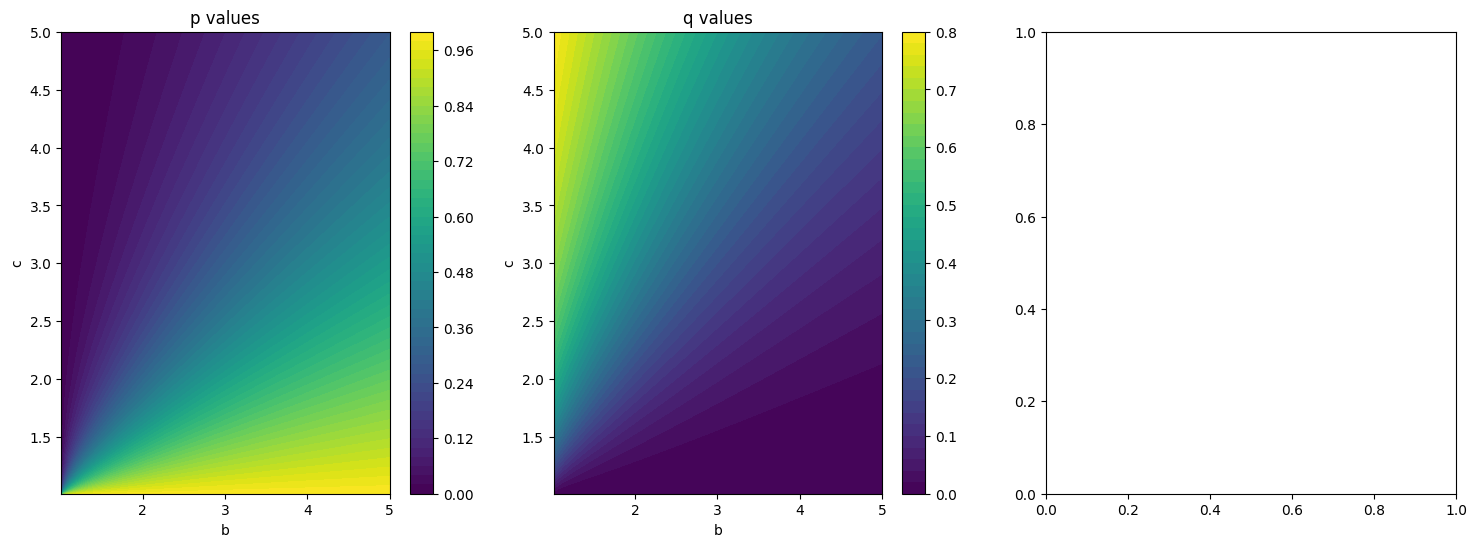

In [2]:
import numpy as np


def p_func(b, c):
    # Compute the denominator; note that the inner term simplifies to (b+c - b**2 - c**2)
    denom = (b + c - 1) * ((b + c) - b**2 - c**2)
    return (b**2 * (1 - b)) / denom

def q_func(b, c):
    p_val = p_func(b, c)
    return (c - b - (1 - b) * p_val) / c

# Define grid for b>1 and c>1. We avoid the singularity at 1 by starting slightly above 1.
b_vals = np.linspace(1.01, 5, 300)
c_vals = np.linspace(1.01, 5, 300)
B, C = np.meshgrid(b_vals, c_vals)

# Compute p and q values on the meshgrid
p_values = p_func(B, C)
q_values = q_func(B, C)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

# Plot p values
c1 = axes[0].contourf(B, C, p_values, levels=50, cmap='viridis')
axes[0].set_title('p values')
axes[0].set_xlabel('b')
axes[0].set_ylabel('c')
fig.colorbar(c1, ax=axes[0])

# Plot q values
c2 = axes[1].contourf(B, C, q_values, levels=50, cmap='viridis')
axes[1].set_title('q values')
axes[1].set_xlabel('b')
axes[1].set_ylabel('c')
fig.colorbar(c2, ax=axes[1])

# Plot validity of p and q
axes[2].scatter(B[inside], C[inside], color='green', s=10, label='Valid: p,q in [0,1]')
axes[2].scatter(B[~inside], C[~inside], color='red', s=10, label='Invalid')
axes[2].set_title('Validity of p and q')
axes[2].set_xlabel('b')
axes[2].set_ylabel('c')
axes[2].legend()

plt.tight_layout()
plt.show()

# Case 1
$b<0$ and $c<1$

\begin{alignat*}{1}
    p &= \frac{b^2\,c}{(b+c-1)\Bigl[2b\,c - b - c + 1\Bigr]},\\[1mm]
    q &= \frac{p\,c - 1}{b-1}\,.
\end{alignat*}

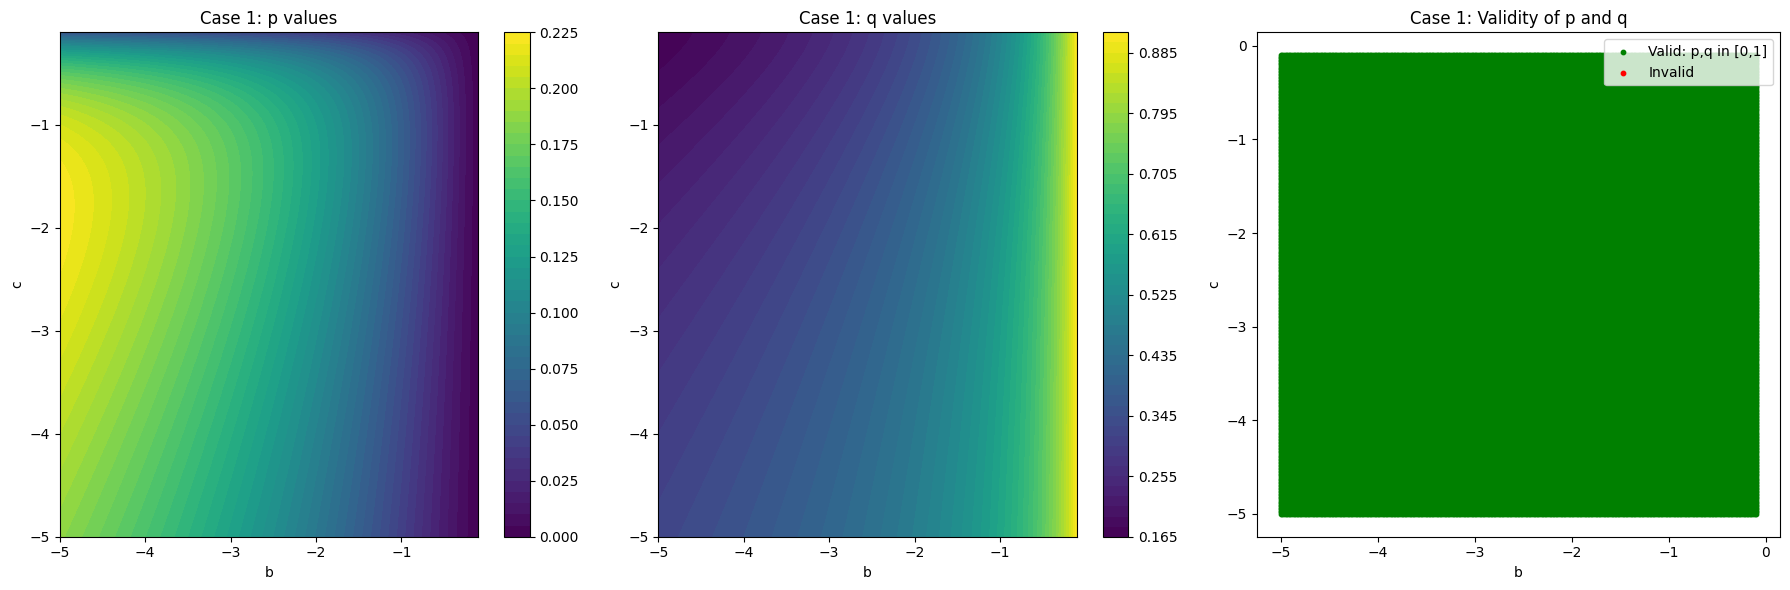

In [4]:
# Functions for Case 1: b < 0 and c < 0
def p_func_case1(b, c):
    # Note: Ensure denominator is not zero.
    denom = (b + c - 1) * (2 * b * c - b - c + 1)
    return (b**2 * c) / denom

def q_func_case1(b, c):
    p_val = p_func_case1(b, c)
    return (p_val * c - 1) / (b - 1)

# Create a grid for b and c for Case 1
b_vals_case1 = np.linspace(-5, -0.1, 300)
c_vals_case1 = np.linspace(-5, -0.1, 300)
B1, C1 = np.meshgrid(b_vals_case1, c_vals_case1)

# Compute p and q values on the grid
p_values_case1 = p_func_case1(B1, C1)
q_values_case1 = q_func_case1(B1, C1)

# Determine the grid points where p and q are valid (i.e., in [0,1])
inside = (p_values_case1 >= 0) & (p_values_case1 <= 1) & (q_values_case1 >= 0) & (q_values_case1 <= 1)

# Create plots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

# Plot p values
c1 = axes[0].contourf(B1, C1, p_values_case1, levels=50, cmap='viridis')
axes[0].set_title('Case 1: p values')
axes[0].set_xlabel('b')
axes[0].set_ylabel('c')
fig.colorbar(c1, ax=axes[0])

# Plot q values
c2 = axes[1].contourf(B1, C1, q_values_case1, levels=50, cmap='viridis')
axes[1].set_title('Case 1: q values')
axes[1].set_xlabel('b')
axes[1].set_ylabel('c')
fig.colorbar(c2, ax=axes[1])

# Plot validity of p and q showing valid points in green and invalid in red
axes[2].scatter(B1[inside], C1[inside], color='green', s=10, label='Valid: p,q in [0,1]')
axes[2].scatter(B1[~inside], C1[~inside], color='red', s=10, label='Invalid')
axes[2].set_title('Case 1: Validity of p and q')
axes[2].set_xlabel('b')
axes[2].set_ylabel('c')
axes[2].legend()

plt.tight_layout()
plt.show()